# VTK River + Shallow Lake Depth Zone Test

This notebook reads paired ASPECT/FastScape `Topography*.vtk` and `SeaLevel*.vtk` files, computes water depth as `sea_level - elevation`, and extracts habitat as river cells OR shallow lake-margin cells.

Default shallow lake habitat is `0 <= water_depth <= 30 m`.

In [1]:
import inspect
import importlib
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
repo_root = next((path for path in (cwd, *cwd.parents) if (path / 'src' / 'magratheamorph').exists()), cwd)
src_path = str(repo_root / 'src')
if src_path in sys.path:
    sys.path.remove(src_path)
sys.path.insert(0, src_path)

import numpy as np
import matplotlib.pyplot as plt

import magratheamorph.model as model_module
import magratheamorph.outputs as outputs_module
import magratheamorph.readers as readers_module
import magratheamorph.visualization as visualization_module
import magratheamorph.vtk_output as vtk_output_module
import magratheamorph.zones as zones_module

# Jupyter keeps imported modules in memory. Reload local code so rerunning this
# notebook uses the latest river/lake masking and VTK writer changes.
model_module = importlib.reload(model_module)
outputs_module = importlib.reload(outputs_module)
readers_module = importlib.reload(readers_module)
visualization_module = importlib.reload(visualization_module)
vtk_output_module = importlib.reload(vtk_output_module)
zones_module = importlib.reload(zones_module)

SpeciationModel = model_module.SpeciationModel
remove_diagnostic_csvs = outputs_module.remove_diagnostic_csvs
write_zone_species_by_time_csv = outputs_module.write_zone_species_by_time_csv
read_vtk_dem = readers_module.read_vtk_dem
read_vtk_sea_level = readers_module.read_vtk_sea_level
with_water_depth = readers_module.with_water_depth
plot_parent_daughter_tree = visualization_module.plot_parent_daughter_tree
plot_richness_map = visualization_module.plot_richness_map
plot_zone_map = visualization_module.plot_zone_map
magrathea_vtk_fields = vtk_output_module.magrathea_vtk_fields
read_legacy_vtk_point_fields = vtk_output_module.read_legacy_vtk_point_fields
write_legacy_vtk_with_point_fields = vtk_output_module.write_legacy_vtk_with_point_fields
write_vtk_series_collection = vtk_output_module.write_vtk_series_collection
ZoneExtractor = zones_module.ZoneExtractor

print('repo root:', repo_root)
print('vtk_output module:', vtk_output_module.__file__)
print('write_legacy_vtk_with_point_fields:', inspect.signature(write_legacy_vtk_with_point_fields))


repo root: /home/ad3.ucdavis.edu/tylxue/Documents/research/code/MagratheaMorph
vtk_output module: /home/ad3.ucdavis.edu/tylxue/Documents/research/code/MagratheaMorph/src/magratheamorph/vtk_output.py
write_legacy_vtk_with_point_fields: (input_path: 'str | Path', output_path: 'str | Path', fields: 'dict[str, np.ndarray]', preserve_existing_point_data: 'bool' = True) -> 'None'


In [33]:
INPUT_DIR = Path('/media/Samsung4TBSSD/research_data/tectonofish/output_fish_3d_t2l1d2/fastscape')
OUTPUT_DIR = Path('fish_3d_t2l1d2_river_lake_depth_magratheamorph_output')
DERIVED_VTK_DIR = OUTPUT_DIR / 'vtk'

HABITAT_MODE = 'drainage_or_shallow_lake'
MIN_DRAINAGE_AREA = 1e8# 100000.0
MIN_LAKE_DEPTH = 0.0
MAX_LAKE_DEPTH = 30.0
SEA_LEVEL_FIELD = 'SL'
MIN_ZONE_CELLS = 100
GAP_TOLERANCE_CELLS = 1
CONNECTIVITY = 8
USE_CATCHMENTS = True
TIME_TO_SPECIATION = 0
MIN_SPECIES_TRANSFER_CELLS = 1
SPECIES_PER_INITIAL_ZONE = 1
SEED_NEW_ZONES = True
TIME_SCALE = 20

# Default is the full time series. Set MAX_FRAMES to a small integer for a quick test.
START_FRAME_INDEX = 0
MAX_FRAMES = None
SELECTED_FRAME_INDEX = -1
TARGET_SPECIES_ID = 0 #None  # set to an integer, e.g. 6, to write magrathea_species_6_presence

all_topography_files = sorted(INPUT_DIR.glob('Topography*.vtk'))
if not all_topography_files:
    raise FileNotFoundError(f'No Topography*.vtk files found in {INPUT_DIR}')

stop = None if MAX_FRAMES is None else START_FRAME_INDEX + MAX_FRAMES
files = all_topography_files[START_FRAME_INDEX:stop]
print('input dir:', INPUT_DIR)
print('selected file count:', len(files), 'of', len(all_topography_files))
print('first:', files[0].name)
print('last:', files[-1].name)
print('max lake depth:', MAX_LAKE_DEPTH)
print('output dir:', OUTPUT_DIR)


input dir: /media/Samsung4TBSSD/research_data/tectonofish/output_fish_3d_t2l1d2/fastscape
selected file count: 51 of 51
first: Topography0000000.vtk
last: Topography0000250.vtk
max lake depth: 30.0
output dir: fish_3d_t2l1d2_river_lake_depth_magratheamorph_output


In [34]:
def suffix_from_topography_name(path):
    return path.stem.replace('Topography', '')

def time_from_topography_name(path):
    return float(suffix_from_topography_name(path)) * TIME_SCALE

def sea_level_path_for(topography_path):
    return INPUT_DIR / f"SeaLevel{suffix_from_topography_name(topography_path)}.vtk"

def read_frame_with_depth(topography_path):
    frame = read_vtk_dem(topography_path, time=time_from_topography_name(topography_path))
    sea_level_path = sea_level_path_for(topography_path)
    if not sea_level_path.exists():
        raise FileNotFoundError(sea_level_path)
    sea_level = read_vtk_sea_level(sea_level_path, sea_level_field=SEA_LEVEL_FIELD)
    return with_water_depth(frame, sea_level)

frames = [read_frame_with_depth(path) for path in files]
sample = frames[0]
print('sample metadata:', sample.metadata)
print('shape:', sample.shape)
print('elevation min/max:', float(np.nanmin(sample.elevation)), float(np.nanmax(sample.elevation)))
print('water depth min/max:', float(np.nanmin(sample.water_depth)), float(np.nanmax(sample.water_depth)))
print('drainage p90/p95/p99/max:', [float(np.nanpercentile(sample.drainage_area, q)) for q in [90, 95, 99]], float(np.nanmax(sample.drainage_area)))


sample metadata: {'path': '/media/Samsung4TBSSD/research_data/tectonofish/output_fish_3d_t2l1d2/fastscape/Topography0000000.vtk', 'reader': 'legacy_vtk_structured_grid', 'elevation_field': 'topography', 'drainage_area_field': 'drainage_area', 'catchment_field': 'catchment', 'water_depth_source': 'sea_level_minus_elevation'}
shape: (227, 227)
elevation min/max: -4.999998092651367 4.99954891204834
water depth min/max: -504.99954891204834 -495.00000190734863
drainage p90/p95/p99/max: [0.0, 0.0, 0.0] 0.0


In [35]:
def make_extractor():
    return ZoneExtractor(
        min_drainage_area=MIN_DRAINAGE_AREA,
        use_catchments=USE_CATCHMENTS,
        connectivity=CONNECTIVITY,
        min_zone_cells=MIN_ZONE_CELLS,
        gap_tolerance_cells=GAP_TOLERANCE_CELLS,
        habitat_mode=HABITAT_MODE,
        min_lake_depth=MIN_LAKE_DEPTH,
        max_lake_depth=MAX_LAKE_DEPTH,
    )

extractor = make_extractor()
model = SpeciationModel(
    time_to_speciation=TIME_TO_SPECIATION,
    seed_new_zones=SEED_NEW_ZONES,
    min_species_transfer_cells=MIN_SPECIES_TRANSFER_CELLS,
)

zone_maps = []
previous = None
for index, frame in enumerate(frames):
    zone_map = extractor.extract(frame, previous=previous)
    zone_maps.append(zone_map)
    if index == 0:
        model.initialize(zone_map, species_per_zone=SPECIES_PER_INITIAL_ZONE)
    else:
        model.step(zone_map)
    previous = zone_map

times = [frame.time for frame in frames]
zone_counts = [len(zone_map.zones) for zone_map in zone_maps]
species_counts = [len({row['species_id'] for row in model.range_table() if row['time'] == zone_map.time}) for zone_map in zone_maps]
print('zone counts:', zone_counts)
print('species counts:', species_counts)


zone counts: [0, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4, 7, 8, 5, 2, 4, 3, 5, 2, 2, 2, 3, 2, 2, 4, 2, 3, 3, 3, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 4, 3, 2, 2]
species counts: [0, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4, 7, 8, 8, 8, 24, 24, 49, 49, 49, 49, 66, 66, 66, 101, 66, 67, 67, 67, 66, 66, 66, 66, 67, 67, 67, 67, 67, 67, 67, 101, 67, 66, 66]


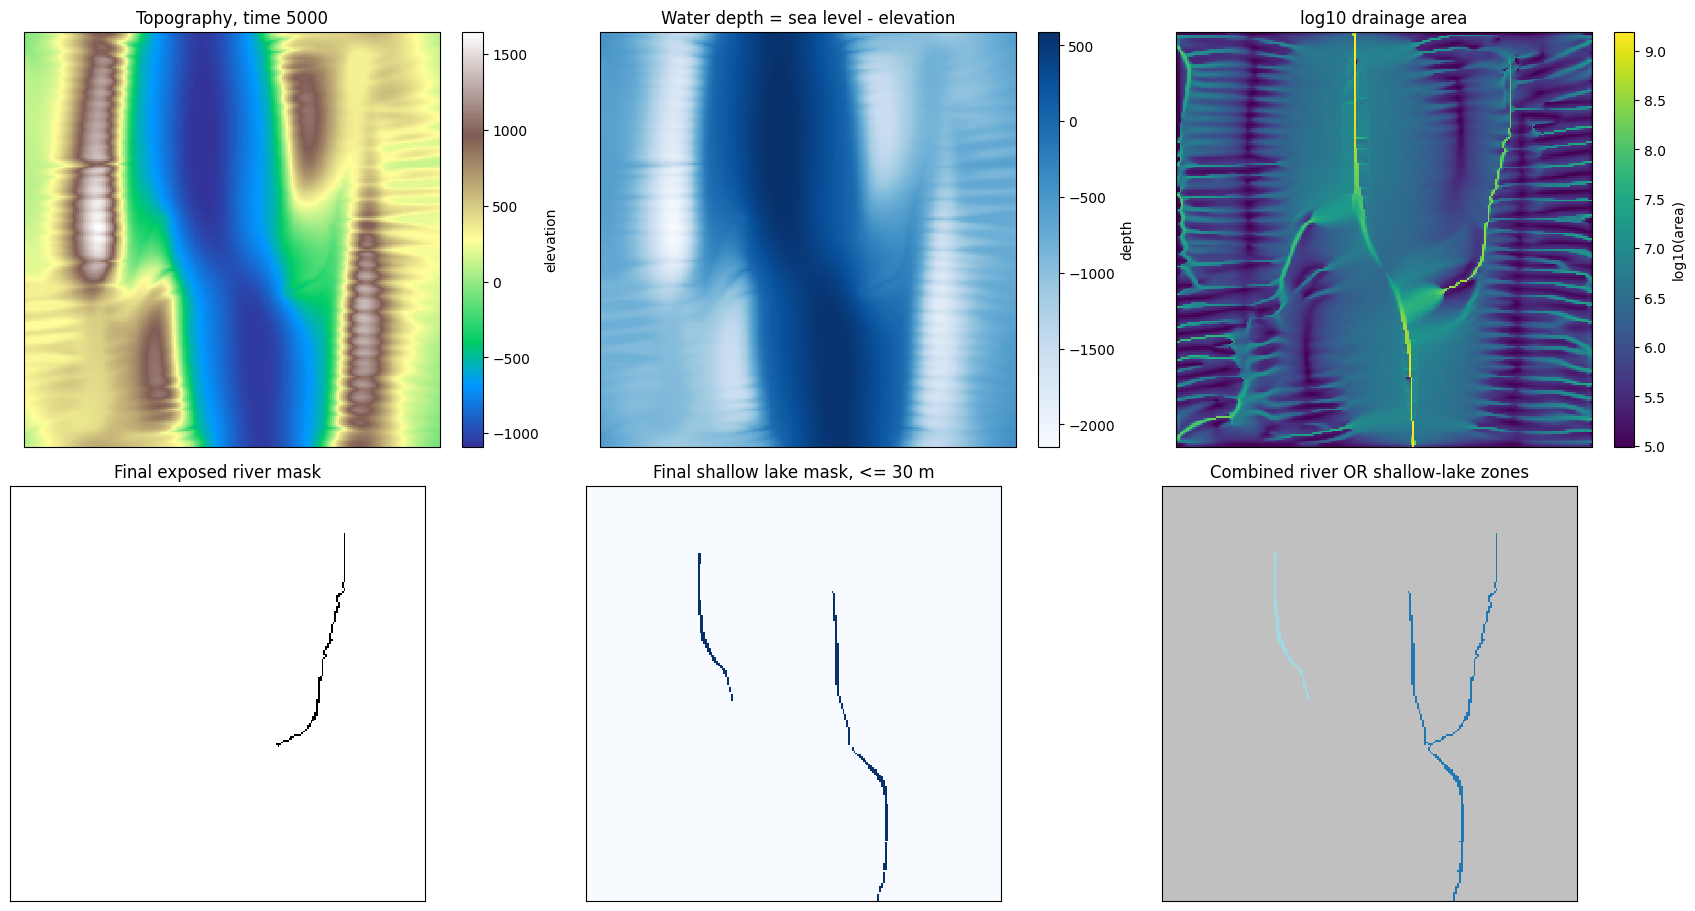

In [36]:
selected_index = SELECTED_FRAME_INDEX if SELECTED_FRAME_INDEX >= 0 else len(frames) + SELECTED_FRAME_INDEX
frame = frames[selected_index]
zone_map = zone_maps[selected_index]

raw_river_mask = frame.drainage_area >= MIN_DRAINAGE_AREA
lake_submerged_mask = frame.water_depth >= 0
final_habitat_mask = zone_map.labels >= 0
river_mask = raw_river_mask & ~lake_submerged_mask & final_habitat_mask
shallow_lake_mask = (frame.water_depth >= MIN_LAKE_DEPTH) & (frame.water_depth <= MAX_LAKE_DEPTH) & ~raw_river_mask & final_habitat_mask
positive_drainage = np.where(frame.drainage_area > 0, frame.drainage_area, np.nan)

fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
im0 = axes[0, 0].imshow(frame.elevation, cmap='terrain', interpolation='nearest')
axes[0, 0].set_title(f'Topography, time {frame.time:g}')
fig.colorbar(im0, ax=axes[0, 0], label='elevation')

im1 = axes[0, 1].imshow(frame.water_depth, cmap='Blues', interpolation='nearest')
axes[0, 1].set_title('Water depth = sea level - elevation')
fig.colorbar(im1, ax=axes[0, 1], label='depth')

im2 = axes[0, 2].imshow(np.log10(positive_drainage), cmap='viridis', interpolation='nearest')
axes[0, 2].set_title('log10 drainage area')
fig.colorbar(im2, ax=axes[0, 2], label='log10(area)')

axes[1, 0].imshow(river_mask, cmap='Greys', interpolation='nearest')
axes[1, 0].set_title('Final exposed river mask')

axes[1, 1].imshow(shallow_lake_mask, cmap='Blues', interpolation='nearest')
axes[1, 1].set_title(f'Final shallow lake mask, <= {MAX_LAKE_DEPTH:g} m')

plot_zone_map(axes[1, 2], zone_map, show_labels=False)
axes[1, 2].set_title('Combined river OR shallow-lake zones')

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()


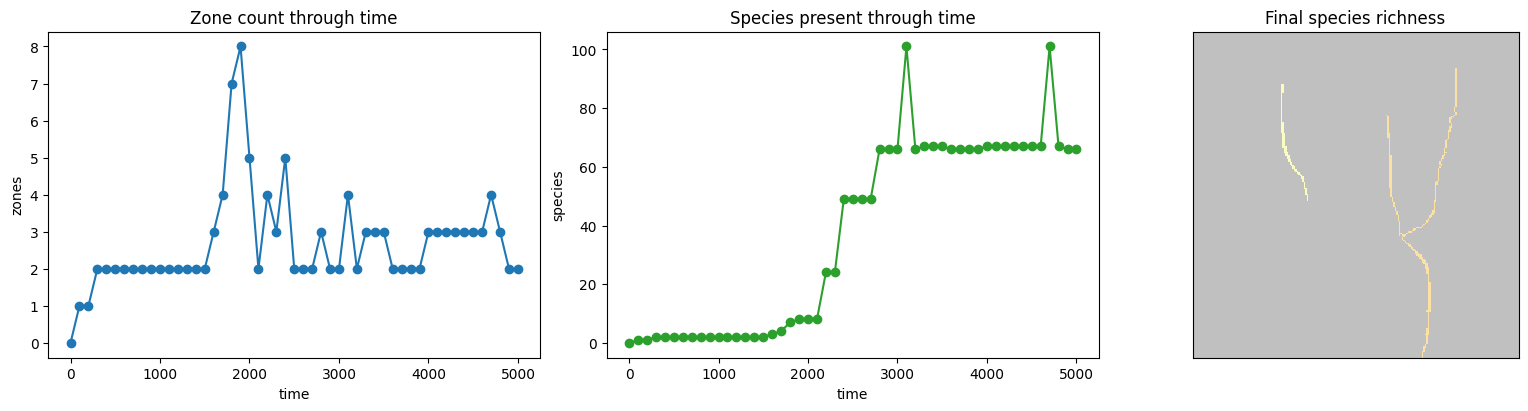

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(times, zone_counts, marker='o')
axes[0].set_title('Zone count through time')
axes[0].set_xlabel('time')
axes[0].set_ylabel('zones')

axes[1].plot(times, species_counts, marker='o', color='tab:green')
axes[1].set_title('Species present through time')
axes[1].set_xlabel('time')
axes[1].set_ylabel('species')

plot_richness_map(axes[2], model, zone_maps[-1], show_labels=False)
axes[2].set_title('Final species richness')
plt.show()


In [38]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DERIVED_VTK_DIR.mkdir(parents=True, exist_ok=True)
for old_vtk in DERIVED_VTK_DIR.glob('*.vtk'):
    old_vtk.unlink()
old_series = OUTPUT_DIR / 'magrathea_timeseries.vtk.series'
if old_series.exists():
    old_series.unlink()

remove_diagnostic_csvs(OUTPUT_DIR)
write_zone_species_by_time_csv(OUTPUT_DIR / 'zone_species_by_time.csv', model, zone_maps)

derived_vtk_paths = []
for input_path, frame, zone_map in zip(files, frames, zone_maps):
    output_path = DERIVED_VTK_DIR / f'{input_path.stem}_magrathea.vtk'
    richness = model.richness_map_at(zone_map)
    fields = magrathea_vtk_fields(zone_map, richness)
    raw_river_mask = frame.drainage_area >= MIN_DRAINAGE_AREA
    lake_submerged_mask = frame.water_depth >= 0
    final_habitat_mask = zone_map.labels >= 0
    river_mask = ((raw_river_mask) & ~lake_submerged_mask & final_habitat_mask).astype(np.int32)
    shallow_lake_mask = ((frame.water_depth >= MIN_LAKE_DEPTH) & (frame.water_depth <= MAX_LAKE_DEPTH) & ~raw_river_mask & final_habitat_mask).astype(np.int32)
    habitat_source = np.zeros(frame.shape, dtype=np.int32)
    habitat_source[river_mask.astype(bool)] = 1
    habitat_source[shallow_lake_mask.astype(bool)] = 2
    fields['magrathea_water_depth'] = frame.water_depth.astype(float)
    fields['magrathea_habitat_mask'] = final_habitat_mask.astype(np.int32)
    fields['magrathea_river_mask'] = river_mask
    fields['magrathea_shallow_lake_mask'] = shallow_lake_mask
    fields['magrathea_habitat_source'] = habitat_source
    if TARGET_SPECIES_ID is not None:
        fields[f'magrathea_species_{int(TARGET_SPECIES_ID)}_presence'] = model.species_presence_map_at(zone_map, int(TARGET_SPECIES_ID)).astype(np.int32)
    write_legacy_vtk_with_point_fields(input_path, output_path, fields, preserve_existing_point_data=False)
    derived_vtk_paths.append(output_path)

series_path = OUTPUT_DIR / 'magrathea_timeseries.vtk.series'
write_vtk_series_collection(series_path, derived_vtk_paths, timesteps=times)

print('wrote zone-species CSV:', (OUTPUT_DIR / 'zone_species_by_time.csv').resolve())
print('derived VTK files:', len(derived_vtk_paths))
print('ParaView time-series file:', series_path.resolve())


wrote zone-species CSV: /home/ad3.ucdavis.edu/tylxue/Documents/research/code/MagratheaMorph/notebooks/fish_3d_t2l1d2_river_lake_depth_magratheamorph_output/zone_species_by_time.csv
derived VTK files: 51
ParaView time-series file: /home/ad3.ucdavis.edu/tylxue/Documents/research/code/MagratheaMorph/notebooks/fish_3d_t2l1d2_river_lake_depth_magratheamorph_output/magrathea_timeseries.vtk.series


In [39]:
# Read back one derived VTK file to confirm expected fields were written.
check_index = selected_index
check_path = DERIVED_VTK_DIR / f'{files[check_index].stem}_magrathea.vtk'
fields = read_legacy_vtk_point_fields(check_path)
print(check_path)
print('field count:', len(fields))
print('fields:', sorted(fields))
print('zone min/max:', int(np.nanmin(fields['magrathea_zone_id'])), int(np.nanmax(fields['magrathea_zone_id'])))
print('richness min/max:', int(np.nanmin(fields['magrathea_species_richness'])), int(np.nanmax(fields['magrathea_species_richness'])))
print('habitat mask min/max:', int(np.nanmin(fields['magrathea_habitat_mask'])), int(np.nanmax(fields['magrathea_habitat_mask'])))
print('water depth min/max:', float(np.nanmin(fields['magrathea_water_depth'])), float(np.nanmax(fields['magrathea_water_depth'])))
print('river mask min/max:', int(np.nanmin(fields['magrathea_river_mask'])), int(np.nanmax(fields['magrathea_river_mask'])))
print('shallow lake mask min/max:', int(np.nanmin(fields['magrathea_shallow_lake_mask'])), int(np.nanmax(fields['magrathea_shallow_lake_mask'])))
print('habitat source values:', sorted(set(fields['magrathea_habitat_source'].astype(int))))
print('zone/habitat mismatch cells:', int(np.count_nonzero((fields['magrathea_zone_id'] >= 0) != (fields['magrathea_habitat_mask'] > 0))))
print('richness outside habitat cells:', int(np.count_nonzero((fields['magrathea_species_richness'] > 0) & (fields['magrathea_habitat_mask'] == 0))))
print('habitat without richness cells:', int(np.count_nonzero((fields['magrathea_habitat_mask'] > 0) & (fields['magrathea_species_richness'] == 0))))
print('submerged river-mask cells:', int(np.count_nonzero((fields['magrathea_river_mask'] > 0) & (fields['magrathea_water_depth'] >= 0))))
print('submerged river-source cells:', int(np.count_nonzero((fields['magrathea_habitat_source'] == 1) & (fields['magrathea_water_depth'] >= 0))))
print('submerged zone cells with river source:', int(np.count_nonzero((fields['magrathea_zone_id'] >= 0) & (fields['magrathea_habitat_source'] == 1) & (fields['magrathea_water_depth'] >= 0))))
if TARGET_SPECIES_ID is not None:
    target_field_name = f'magrathea_species_{int(TARGET_SPECIES_ID)}_presence'
    print('target species field:', target_field_name)
    print('target species presence min/max:', int(np.nanmin(fields[target_field_name])), int(np.nanmax(fields[target_field_name])))


fish_3d_t2l1d2_river_lake_depth_magratheamorph_output/vtk/Topography0000250_magrathea.vtk
field count: 8
fields: ['magrathea_habitat_mask', 'magrathea_habitat_source', 'magrathea_river_mask', 'magrathea_shallow_lake_mask', 'magrathea_species_0_presence', 'magrathea_species_richness', 'magrathea_water_depth', 'magrathea_zone_id']
zone min/max: -1 19
richness min/max: 0 34
habitat mask min/max: 0 1
water depth min/max: -2147.91748046875 590.1591796875
river mask min/max: 0 1
shallow lake mask min/max: 0 1
habitat source values: [np.int64(0), np.int64(1), np.int64(2)]
zone/habitat mismatch cells: 0
richness outside habitat cells: 0
habitat without richness cells: 0
submerged river-mask cells: 0
submerged river-source cells: 0
submerged zone cells with river source: 0
target species field: magrathea_species_0_presence
target species presence min/max: 0 1


## Parent-daughter species tree

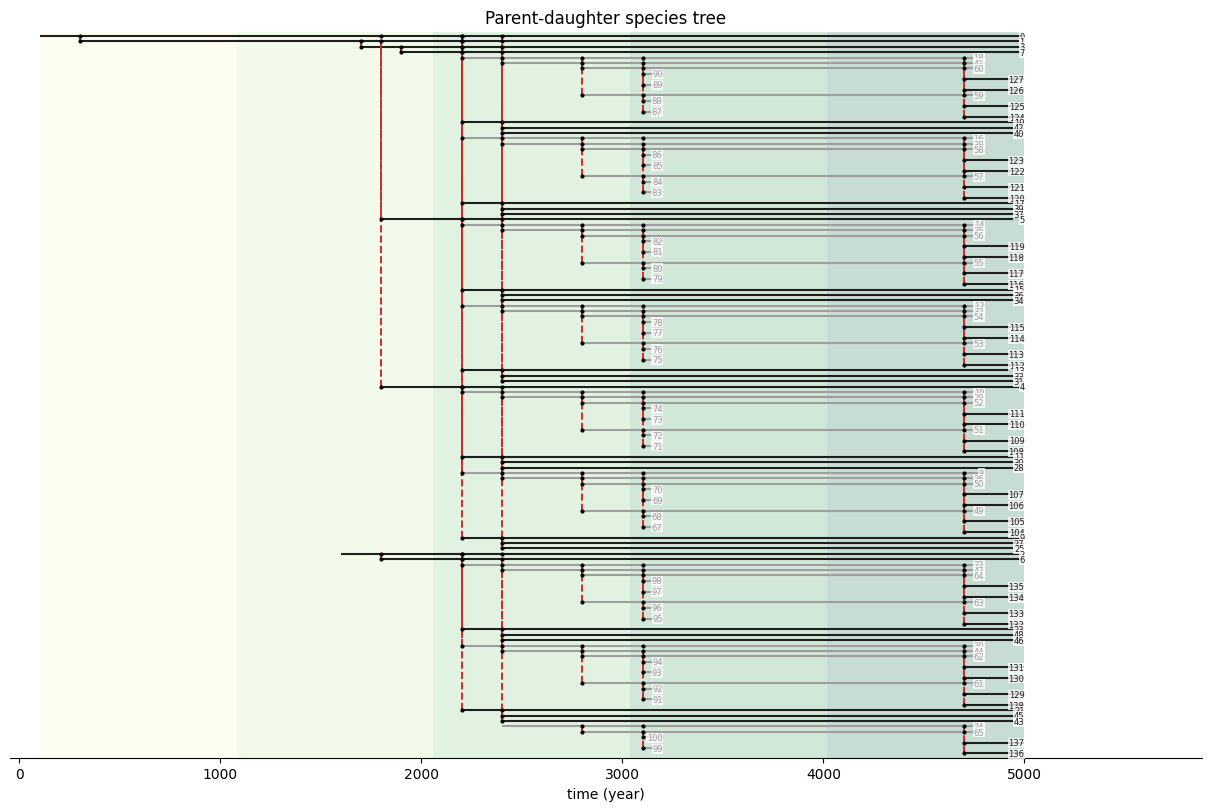

In [40]:
species_rows = model.species_table()
fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
plot_parent_daughter_tree(
    ax,
    species_rows,
    end_time=max(times),
    label_mode='all',
    style='rectangular',
    time_unit='year',
    label_position='end',
    label_fontsize=6,
    show_time_blocks=True,
    time_block_cmap='YlGn',
    split_marker=True,
    split_marker_color='black',
    split_marker_size=2,
)
plt.show()


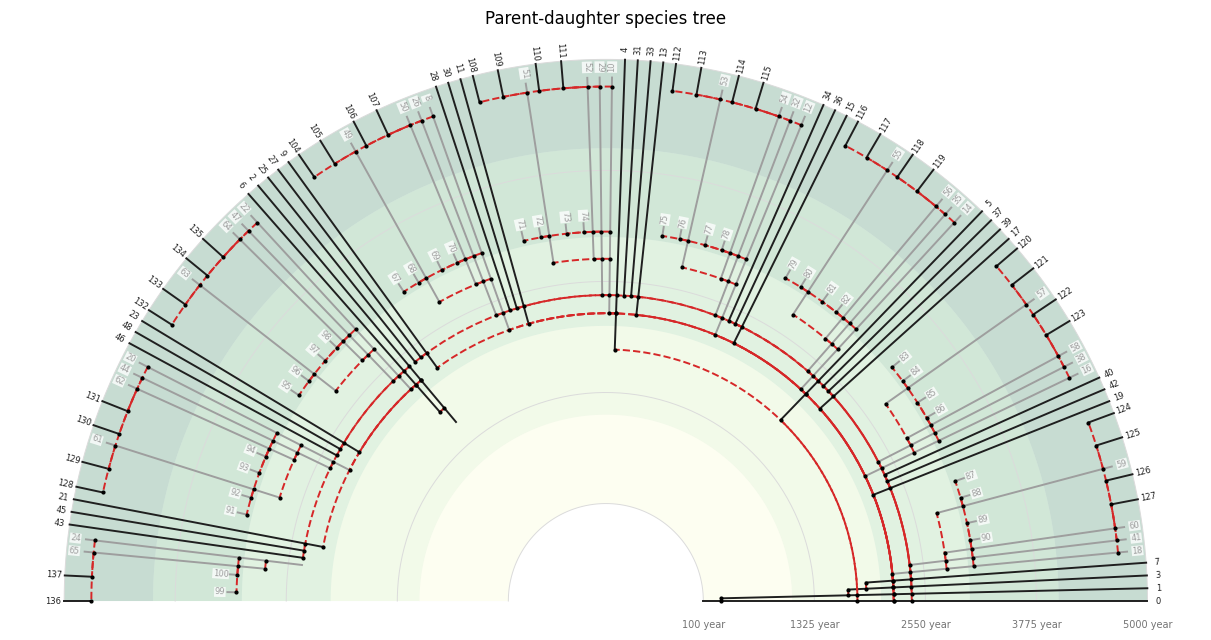

In [41]:
species_rows = model.species_table()
fig, ax = plt.subplots(figsize=(12, 12), constrained_layout=True)
plot_parent_daughter_tree(
    ax,
    species_rows,
    end_time=max(times),
    label_mode='all',
    style='semicircle',
    time_unit='year',
    label_position='end',
    label_fontsize=6,
    show_time_blocks=True,
    time_block_cmap='YlGn',
    split_marker=True,
    split_marker_color='black',
    split_marker_size=2,
)
plt.show()
